# Netflix Movies and TV Shows – Data Analysis

## Project Overview
This project analyses the Netflix Movies and TV Shows dataset using Python.

The purpose of this project is to explore Netflix content, understand its distribution, identify popular genres, and discover patterns in the dataset.

## Dataset Source
Kaggle – Netflix Movies and TV Shows Dataset

https://www.kaggle.com/datasets/shivamb/netflix-shows

## Tools and Libraries Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Analysis Performed
1. Imported the Netflix CSV dataset.
2. Explored dataset structure and statistical information.
3. Compared Movies and TV Shows.
4. Analysed Netflix content by country.
5. Examined content by release year.
6. Identified and handled missing values.
7. Analysed the most common Netflix genres.
8. Created visualizations using Matplotlib.

## Project Goal
To practise data importing, data cleaning, exploratory data analysis, and data visualization using Python.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("netflix_titles.csv")

print("Netflix dataset imported successfully!")

Netflix dataset imported successfully!


In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.shape

(8807, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [6]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
content_count = df["type"].value_counts()

print(content_count)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [8]:
content_percentage = df["type"].value_counts(normalize=True) * 100

print(content_percentage.round(2))

type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


### Finding 1: Movies vs TV Shows

The Netflix dataset contains both Movies and TV Shows.
Movies make up the larger share of the dataset.
This shows that movies are more common than TV Shows
in the available Netflix titles.

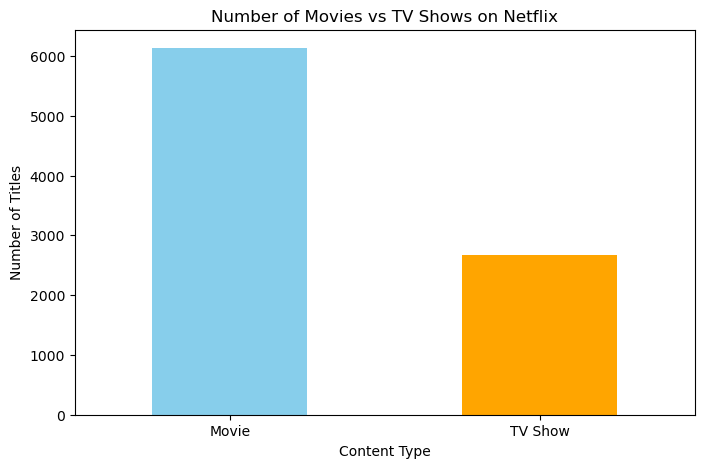

In [9]:
plt.figure(figsize=(8, 5))

content_count.plot(kind="bar", color=["skyblue", "orange"])

plt.title("Number of Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.xticks(rotation=0)
plt.show()

### Chart 1: Movies vs TV Shows

The bar chart shows that Netflix has more Movies
than TV Shows. Movies represent the majority of
the content in this dataset.

In [10]:
country_data = df["country"].dropna()

country_list = country_data.str.split(", ").explode()

country_count = country_list.value_counts()

print(country_count.head(10))

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


In [11]:
top_10_countries = country_count.head(10)

print(top_10_countries)

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


### Finding 2: Netflix Content by Country

The country analysis shows that the United States
is one of the major producers of Netflix content.
India and the United Kingdom also contribute
a significant number of titles.

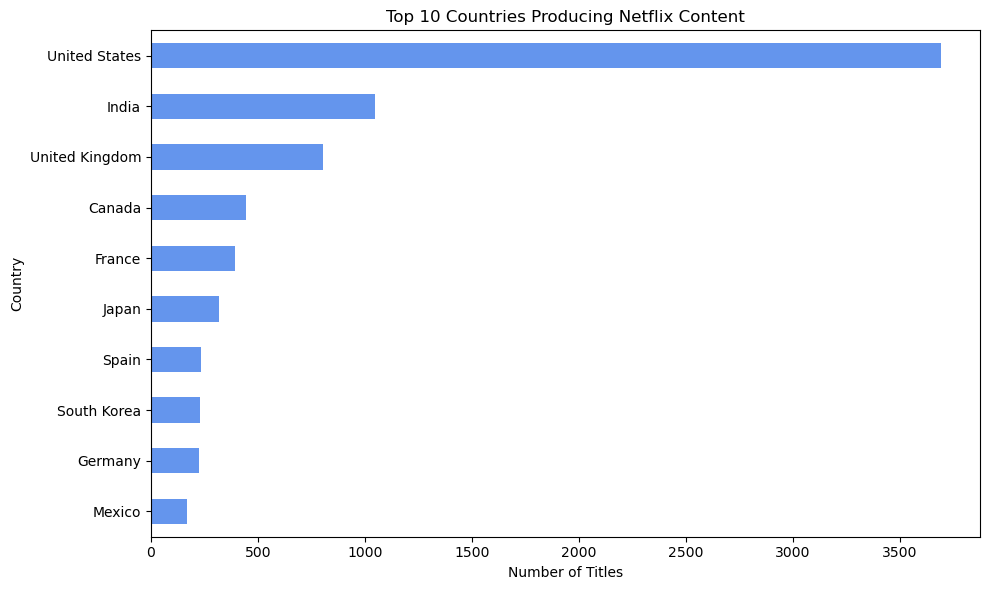

In [12]:
plt.figure(figsize=(10, 6))

top_10_countries.sort_values().plot(
    kind="barh",
    color="cornflowerblue"
)

plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

### Chart 2: Top 10 Countries

The horizontal bar chart compares the number of
Netflix titles across the top 10 countries.

The United States has the highest number of titles
in this dataset, followed by other major content-
producing countries.

In [13]:
year_count = df["release_year"].value_counts().sort_index()

print(year_count)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


In [14]:
top_10_years = year_count.sort_values(ascending=False).head(10)

print(top_10_years)

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64


### Finding 3: Netflix Content by Release Year

The release year analysis shows that Netflix has
content from different decades.

The number of titles varies across years, with
some recent years having more releases than others.

In [15]:
missing_values = df.isnull().sum()

print(missing_values)

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.round(2))

show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64


### Finding 4: Missing Values

The Netflix dataset contains missing values in
some columns, especially director, cast and country.

Identifying missing values is important because
it helps us understand the quality of our dataset
before performing further analysis.

In [17]:
df_cleaned = df.copy()

df_cleaned["director"] = df_cleaned["director"].fillna("Unknown")

df_cleaned["cast"] = df_cleaned["cast"].fillna("Unknown")

df_cleaned["country"] = df_cleaned["country"].fillna("Unknown")

print("Missing values handled successfully!")

Missing values handled successfully!


In [18]:
df_cleaned[["director", "cast", "country"]].isnull().sum()

director    0
cast        0
country     0
dtype: int64

In [19]:
print("Missing values before cleaning:")
print(df[["director", "cast", "country"]].isnull().sum())

print("\nMissing values after cleaning:")
print(df_cleaned[["director", "cast", "country"]].isnull().sum())

Missing values before cleaning:
director    2634
cast         825
country      831
dtype: int64

Missing values after cleaning:
director    0
cast        0
country     0
dtype: int64


### Finding 5: Data Cleaning

I handled missing values in the director, cast
and country columns by replacing them with
"Unknown".

This helped preserve the original records while
making these columns easier to work with.

In [20]:
genre_data = df_cleaned["listed_in"]

genre_list = genre_data.str.split(", ").explode()

genre_count = genre_list.value_counts()

print(genre_count.head(10))

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [21]:
top_10_genres = genre_count.head(10)

print(top_10_genres)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


### Finding 6: Netflix Genres

The genre analysis shows that Netflix contains
different types of entertainment content.

Some genres appear more frequently than others.
This helps us understand the types of content
available on Netflix.

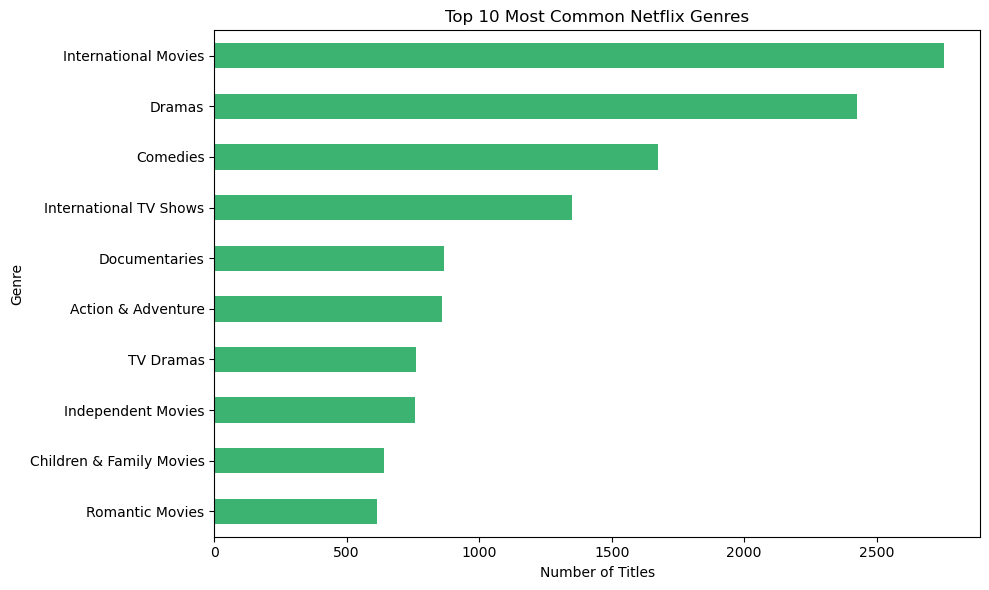

In [22]:
plt.figure(figsize=(10, 6))

top_10_genres.sort_values().plot(
    kind="barh",
    color="mediumseagreen"
)

plt.title("Top 10 Most Common Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### Chart 3: Top 10 Netflix Genres

The chart compares the ten most common genres
in the Netflix dataset.

It shows that some genres have significantly
more titles than others.

# Final Findings and Conclusion

## Key Findings

1. **Movies vs TV Shows:** The dataset contains more Movies than TV Shows.

2. **Country Analysis:** The United States is a major contributor to Netflix content. India and the United Kingdom are also among the leading countries.

3. **Release Year Analysis:** Netflix contains titles released across different years, with varying numbers of releases in each year.

4. **Missing Values:** Some columns, especially director, cast and country, contain missing information.

5. **Data Cleaning:** Missing values in the director, cast and country columns were replaced with "Unknown".

6. **Genre Analysis:** The dataset contains many genres, and some genres appear more frequently than others.

## Conclusion

Through this project, I learned how to import CSV files using Pandas, explore datasets, calculate statistics, identify and handle missing values, and create visualizations using Matplotlib.

This project helped me understand the basic process of Exploratory Data Analysis (EDA) using Python.